In [1]:
# 1. Importação das bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

In [2]:
# 2. Carregamento da base de dados (RAIS 2023 - Construção Civil MA)
df = pd.read_csv('../data/base_de_dados.csv', sep=',', decimal='.', encoding='latin-1')
df.columns = df.columns.str.strip()
print(f"Base inicial: {df.shape[0]} registros | {df.shape[1]} colunas")

Base inicial: 97971 registros | 67 colunas


In [3]:
# 3. Remoção das 12 colunas descartadas na TED 02
colunas_remover = [
    'ano',
    'sigla_uf',
    'causa_desligamento_1',
    'causa_desligamento_2',
    'causa_desligamento_3',
    'cbo_1994',
    'cnae_1',
    'bairros_sp',
    'distritos_sp',
    'bairros_fortaleza',
    'bairros_rj',
    'regioes_administrativas_df'
]

df_trabalho = df.drop(columns=[c for c in colunas_remover if c in df.columns])
print(f"Após remoção de colunas: {df_trabalho.shape[0]} registros | {df_trabalho.shape[1]} colunas")

Após remoção de colunas: 97971 registros | 55 colunas


In [4]:
# 4. Remoção de duplicidades e filtragem de remuneração > 0
duplicatas = df_trabalho.duplicated().sum()
df_trabalho = df_trabalho.drop_duplicates()
print(f"Duplicatas removidas: {duplicatas}")

df_modelo = df_trabalho[df_trabalho['valor_remuneracao_media'] > 0].copy()
print(f"Registros válidos para treino (remuneração > 0): {df_modelo.shape[0]}")

Duplicatas removidas: 542


Registros válidos para treino (remuneração > 0): 85755


In [5]:
# 5. Definição das variáveis preditoras (X) e alvo (y)
variaveis_categoricas = ['cbo_2002', 'cnae_2', 'sexo', 'tamanho_estabelecimento', 'tipo_vinculo']
variaveis_numericas = ['idade', 'quantidade_horas_contratadas', 'tempo_emprego']
variavel_alvo = 'valor_remuneracao_media'

# Conversão das variáveis categóricas para string
for col in variaveis_categoricas:
    df_modelo[col] = df_modelo[col].astype(str)

X = df_modelo[variaveis_categoricas + variaveis_numericas]
y = df_modelo[variavel_alvo]

print(f"X shape: {X.shape} | y shape: {y.shape}")

X shape: (85755, 8) | y shape: (85755,)


In [6]:
# 6. Divisão dos dados em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")

Treino: 68604 amostras | Teste: 17151 amostras


In [7]:
# 7. Configuração do pré-processamento via ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), variaveis_categoricas),
        ('num', SimpleImputer(strategy='median'), variaveis_numericas)
    ],
    remainder='drop'
)

In [8]:
# 8. Criação e treinamento dos pipelines (Baseline e Regressão Linear)
pipeline_baseline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DummyRegressor(strategy='mean'))
])

pipeline_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

pipeline_baseline.fit(X_train, y_train)
pipeline_lr.fit(X_train, y_train)
print("Treinamento dos modelos concluído.")

Treinamento dos modelos concluído.


In [9]:
# 9. Previsões e cálculo das métricas de avaliação
y_pred_baseline = pipeline_baseline.predict(X_test)
y_pred_lr = pipeline_lr.predict(X_test)

def calcular_metricas(y_real, y_pred, nome_modelo):
    mae = mean_absolute_error(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_real, y_pred)
    return {
        'Modelo': nome_modelo,
        'MAE (R$)': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE (R$)': round(rmse, 2),
        'R²': round(r2, 4)
    }

metricas_baseline = calcular_metricas(y_test, y_pred_baseline, 'DummyRegressor (Baseline)')
metricas_lr = calcular_metricas(y_test, y_pred_lr, 'LinearRegression')

df_resultados = pd.DataFrame([metricas_baseline, metricas_lr]).set_index('Modelo')
print("=== COMPARAÇÃO DOS MODELOS ===")
print(df_resultados.to_string())

=== COMPARAÇÃO DOS MODELOS ===
                           MAE (R$)         MSE  RMSE (R$)     R²
Modelo                                                           
DummyRegressor (Baseline)    995.09  2846010.87    1687.01 -0.000
LinearRegression             634.03  1494122.98    1222.34  0.475


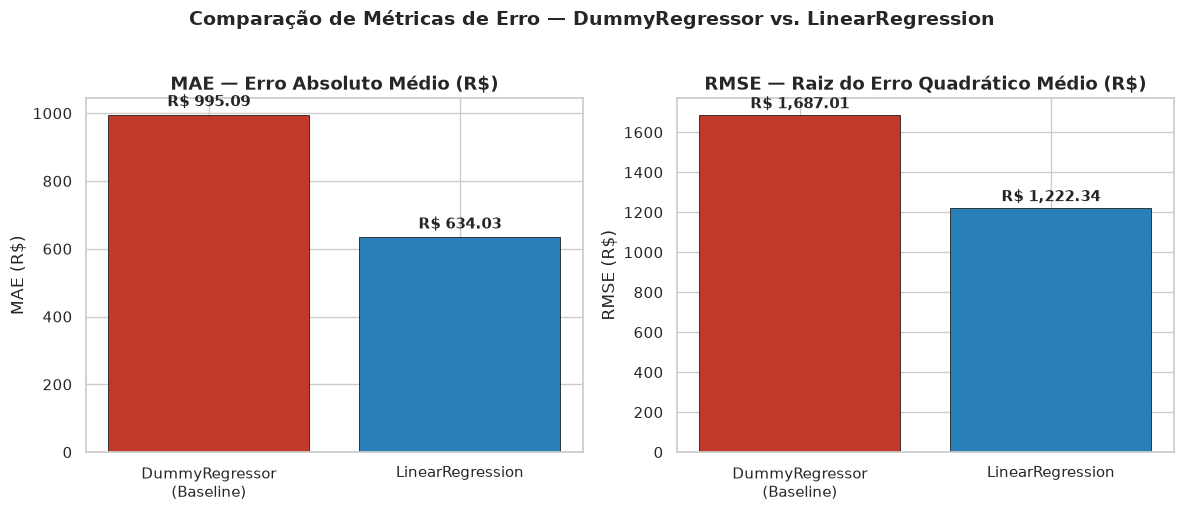

In [10]:
# 10. Gráfico 1: Comparação de MAE e RMSE entre os modelos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
modelos = ['DummyRegressor\n(Baseline)', 'LinearRegression']
cores = ['#c0392b', '#2980b9']

valores_mae = [metricas_baseline['MAE (R$)'], metricas_lr['MAE (R$)']]
bars_mae = axes[0].bar(modelos, valores_mae, color=cores, edgecolor='black', linewidth=0.5)
axes[0].set_title('MAE — Erro Absoluto Médio (R$)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('MAE (R$)')
for bar, val in zip(bars_mae, valores_mae):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
                 f'R$ {val:,.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

valores_rmse = [metricas_baseline['RMSE (R$)'], metricas_lr['RMSE (R$)']]
bars_rmse = axes[1].bar(modelos, valores_rmse, color=cores, edgecolor='black', linewidth=0.5)
axes[1].set_title('RMSE — Raiz do Erro Quadrático Médio (R$)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('RMSE (R$)')
for bar, val in zip(bars_rmse, valores_rmse):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
                 f'R$ {val:,.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.suptitle('Comparação de Métricas de Erro — DummyRegressor vs. LinearRegression', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../data/grafico_comparacao_metricas.png', dpi=150, bbox_inches='tight')
plt.show()

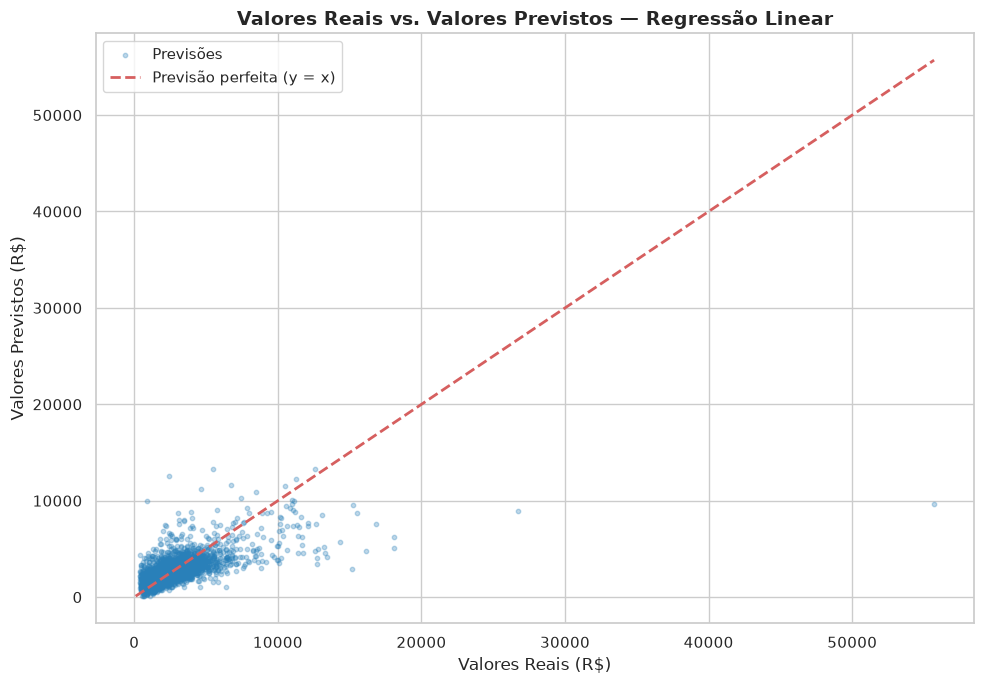

In [ ]:
# 11. Gráfico 2: Valores Reais vs. Valores Previstos (LinearRegression)
fig, ax = plt.subplots(figsize=(10, 7))
n_amostra = min(5000, len(y_test))
np.random.seed(42)
indices = np.random.choice(len(y_test), size=n_amostra, replace=False)

y_test_amostra = y_test.iloc[indices]
y_pred_amostra = y_pred_lr[indices]

ax.scatter(y_test_amostra, y_pred_amostra, alpha=0.3, s=10, color='#2980b9', label='Previsões')
limite_max = max(y_test_amostra.max(), y_pred_amostra.max())
limite_min = min(y_test_amostra.min(), y_pred_amostra.min())
ax.plot([limite_min, limite_max], [limite_min, limite_max], 'r--', linewidth=2, label='Previsão perfeita (y = x)')

ax.set_xlabel('Valores Reais (R$)', fontsize=12)
ax.set_ylabel('Valores Previstos (R$)', fontsize=12)
ax.set_title('Valores Reais vs. Valores Previstos — Regressão Linear', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('../data/grafico_real_vs_previsto.png', dpi=150, bbox_inches='tight')
plt.show()

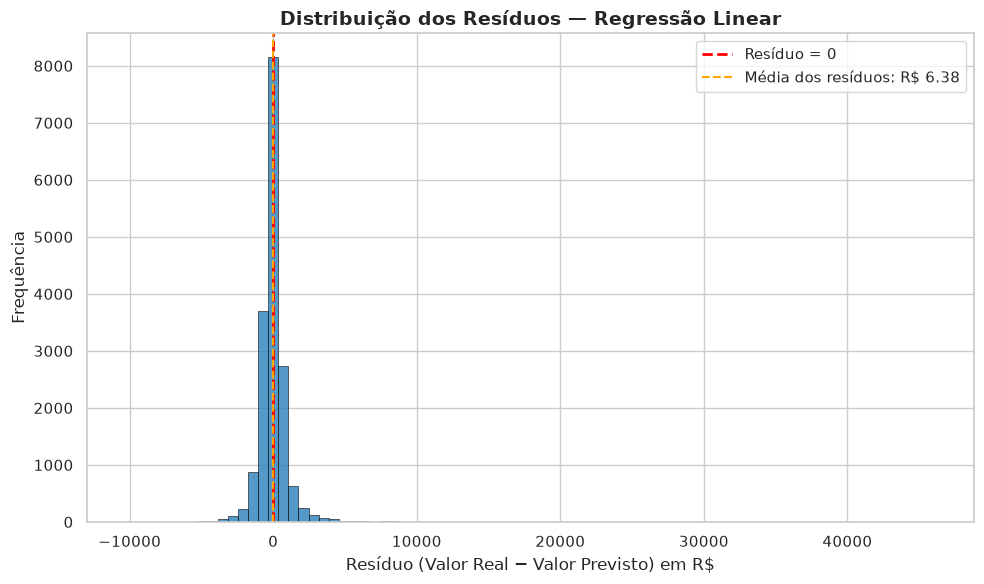

Resíduos - Média: R$ 6.38 | Mediana: R$ -44.11 | Desvio Padrão: R$ 1,222.33


In [12]:
# 12. Gráfico 3: Distribuição dos Resíduos (Valores Reais - Valores Previstos)
residuos = y_test.values - y_pred_lr
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(residuos, bins=80, color='#2980b9', edgecolor='black', linewidth=0.5, alpha=0.8)
ax.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Resíduo = 0')
ax.axvline(x=np.mean(residuos), color='orange', linestyle='--', linewidth=1.5,
           label=f'Média dos resíduos: R$ {np.mean(residuos):,.2f}')

ax.set_xlabel('Resíduo (Valor Real − Valor Previsto) em R$', fontsize=12)
ax.set_ylabel('Frequência', fontsize=12)
ax.set_title('Distribuição dos Resíduos — Regressão Linear', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('../data/grafico_distribuicao_residuos.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Resíduos - Média: R$ {np.mean(residuos):,.2f} | Mediana: R$ {np.median(residuos):,.2f} | Desvio Padrão: R$ {np.std(residuos):,.2f}")